# Automobile Price: Exploratory Data Analysis

**Student:** Nuwarinda  
Access Number: B38638
Student Number: S26M19/017
Git hub link: https://github.com/RNuwarinda/Assignment-1_Nuwarinda
**Objective:** identify vehicle attributes associated with automobile price using descriptive statistics, visual analysis, group comparisons, and a univariate feature-selection filter.

The supplied file contains 201 records and 29 columns. `price` is the outcome. Results describe associations in this sample; they do not establish that an attribute causes a price change. The notebook keeps the source file unchanged and writes the cleaned data to `Nuwarinda_Data.csv` beside the source.

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 60)
plt.style.use("ggplot")

candidate_paths = [
    Path("automobileEDA.csv"),
    Path("automobileEDA(2).csv"),
    Path("Assignment-1_Nuwarinda") / "automobileEDA(2).csv",
    Path("Assignment-1_Nuwarinda") / "automobileEDA.csv",
]
source_path = next((path.resolve() for path in candidate_paths if path.exists()), None)
if source_path is None:
    raise FileNotFoundError(
        "Could not find automobileEDA.csv or automobileEDA(2).csv in the notebook "
        "folder or its Assignment-1_Nuwarinda subfolder."
    )

raw_df = pd.read_csv(source_path)
print(f"Source file: {source_path.name}")
print(f"Dataset dimensions: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
print("The first five rows show the available vehicle attributes and target:")
display(raw_df.head())
print("\nColumn data types:")
display(raw_df.dtypes.rename("data_type").to_frame())

Source file: automobileEDA(2).csv
Dataset dimensions: 201 rows x 29 columns
The first five rows show the available vehicle attributes and target:


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450,13.055556,Medium,0,1



Column data types:


,data_type
symboling,int64
normalized-losses,int64
make,str
aspiration,str
num-of-doors,str
body-style,str
drive-wheels,str
engine-location,str
wheel-base,float64
length,float64


## 1. Data quality, cleaning, and outliers

First, inspect missingness and exact duplicate rows. Numeric gaps are imputed with that column's median; categorical gaps use the most frequent category. Rows without a target price would be excluded rather than inventing an outcome. The 1.5-IQR rule is used to *flag* unusual continuous values. A statistical flag is not by itself evidence of an error: flagged values were reviewed, no impossible vehicle values were identified, and all are retained rather than deleted or capped. This preserves genuine luxury cars and the dealer-relevant market range.

In [3]:
missing_before = raw_df.isna().sum()
missing_before = missing_before[missing_before.gt(0)].rename("missing_values").to_frame()
print("Columns with missing values before cleaning (an empty table means none):")
display(missing_before)

duplicate_count = int(raw_df.duplicated().sum())
print(f"Exact duplicate rows before cleaning: {duplicate_count}")

cleaned_df = raw_df.drop_duplicates().copy()
missing_target_count = int(cleaned_df["price"].isna().sum())
if missing_target_count:
    cleaned_df = cleaned_df.dropna(subset=["price"]).copy()
    print(f"Rows excluded because target price was missing: {missing_target_count}")
else:
    print("Rows excluded for missing target price: 0")

numeric_columns = cleaned_df.select_dtypes(include="number").columns.tolist()
categorical_columns = cleaned_df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()
imputation_log = []
for column in numeric_columns:
    count = int(cleaned_df[column].isna().sum())
    if count:
        median_value = cleaned_df[column].median()
        cleaned_df[column] = cleaned_df[column].fillna(median_value)
        imputation_log.append(
            {"column": column, "missing_filled": count, "method": "median", "value": median_value}
        )
for column in categorical_columns:
    count = int(cleaned_df[column].isna().sum())
    if count:
        mode_values = cleaned_df[column].mode(dropna=True)
        if mode_values.empty:
            raise ValueError(f"Cannot impute {column}: no non-missing category is available.")
        mode_value = mode_values.iloc[0]
        cleaned_df[column] = cleaned_df[column].fillna(mode_value)
        imputation_log.append(
            {"column": column, "missing_filled": count, "method": "mode", "value": mode_value}
        )

imputation_table = pd.DataFrame(
    imputation_log, columns=["column", "missing_filled", "method", "value"]
)
print("Imputation actions (an empty table means no imputation was needed):")
display(imputation_table)

continuous_columns = [
    column
    for column in numeric_columns
    if column not in {"symboling", "diesel", "gas"}
    and cleaned_df[column].nunique(dropna=True) > 2
]
outlier_rows = []
for column in continuous_columns:
    q1 = cleaned_df[column].quantile(0.25)
    q3 = cleaned_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    count = int(((cleaned_df[column] < lower_fence) | (cleaned_df[column] > upper_fence)).sum())
    if count:
        outlier_rows.append(
            {
                "feature": column,
                "outlier_count": count,
                "lower_fence": lower_fence,
                "upper_fence": upper_fence,
            }
        )
outlier_table = pd.DataFrame(
    outlier_rows, columns=["feature", "outlier_count", "lower_fence", "upper_fence"]
).sort_values("outlier_count", ascending=False)
print("Continuous-feature values outside 1.5-IQR fences; these are review flags, not automatic deletions:")
display(outlier_table)

price_q1, price_q3 = cleaned_df["price"].quantile([0.25, 0.75])
price_upper_fence = price_q3 + 1.5 * (price_q3 - price_q1)
high_price_rows = cleaned_df.loc[
    cleaned_df["price"] > price_upper_fence,
    ["make", "body-style", "drive-wheels", "engine-size", "horsepower", "price"],
].sort_values("price", ascending=False)
print(
    f"Price IQR upper fence: {price_upper_fence:,.2f}; "
    f"high-price rows reviewed: {len(high_price_rows)}."
)
print("The listed observations have plausible vehicle makes/specifications, so they are retained.")
display(high_price_rows)

cleaned_path = source_path.parent / "Nuwarinda_Data.csv"
cleaned_df.to_csv(cleaned_path, index=False)
saved_df = pd.read_csv(cleaned_path)
print(
    f"Saved cleaned dataset: {cleaned_path.name} "
    f"({saved_df.shape[0]} rows x {saved_df.shape[1]} columns)."
)
print(f"Missing values remaining: {int(saved_df.isna().sum().sum())}")
print(f"Exact duplicate rows remaining: {int(saved_df.duplicated().sum())}")
display(saved_df.isna().sum().rename("missing_after_cleaning").to_frame().query("missing_after_cleaning > 0"))

Columns with missing values before cleaning (an empty table means none):


,missing_values
stroke,4
horsepower-binned,1


Exact duplicate rows before cleaning: 0
Rows excluded for missing target price: 0
Imputation actions (an empty table means no imputation was needed):


,column,missing_filled,method,value
0,stroke,4,median,3.29
1,horsepower-binned,1,mode,Low


Continuous-feature values outside 1.5-IQR fences; these are review flags, not automatic deletions:


,feature,outlier_count,lower_fence,upper_fence
7,compression-ratio,27,7.400000,10.600000
6,stroke,20,2.660000,3.860000
12,price,14,-5312.500000,29587.500000
3,width,11,0.838194,0.977083
5,engine-size,10,33.500000,205.500000
0,normalized-losses,8,47.000000,191.000000
8,horsepower,5,1.000000,185.000000
1,wheel-base,3,82.650000,114.250000
11,highway-mpg,3,11.500000,47.500000
10,city-mpg,2,2.500000,46.500000


Price IQR upper fence: 29,587.50; high-price rows reviewed: 14.
The listed observations have plausible vehicle makes/specifications, so they are retained.


,make,body-style,drive-wheels,engine-size,horsepower,price
71,mercedes-benz,hardtop,rwd,304,184.0,45400
15,bmw,sedan,rwd,209,182.0,41315
70,mercedes-benz,sedan,rwd,308,184.0,40960
125,porsche,convertible,rwd,194,207.0,37028
16,bmw,sedan,rwd,209,182.0,36880
46,jaguar,sedan,rwd,326,262.0,36000
45,jaguar,sedan,rwd,258,176.0,35550
69,mercedes-benz,convertible,rwd,234,155.0,35056
68,mercedes-benz,sedan,rwd,234,155.0,34184
124,porsche,hardtop,rwd,194,207.0,34028


Saved cleaned dataset: Nuwarinda_Data.csv (201 rows x 29 columns).
Missing values remaining: 0
Exact duplicate rows remaining: 0


,missing_after_cleaning


## 2. Descriptive statistics and distributions

The next tables summarize every continuous numeric column and give frequency counts for every categorical column. The figures show the target distribution, continuous-feature distributions, and category frequencies. Expect price to be right-skewed: a small number of expensive models can pull the mean above the median. Axes and category labels are kept explicit so the graphics can be interpreted independently of the code.

Summary statistics for continuous numeric variables:


,count,mean,std,min,25%,50%,75%,max
normalized-losses,201.0,122.000000,31.996250,65.000000,101.000000,122.000000,137.000000,256.000000
wheel-base,201.0,98.797015,6.066366,86.600000,94.500000,97.000000,102.400000,120.900000
length,201.0,0.837102,0.059213,0.678039,0.801538,0.832292,0.881788,1.000000
width,201.0,0.915126,0.029187,0.837500,0.890278,0.909722,0.925000,1.000000
height,201.0,53.766667,2.447822,47.800000,52.000000,54.100000,55.500000,59.800000
curb-weight,201.0,2555.666667,517.296727,1488.000000,2169.000000,2414.000000,2926.000000,4066.000000
engine-size,201.0,126.875622,41.546834,61.000000,98.000000,120.000000,141.000000,326.000000
bore,201.0,3.330692,0.268072,2.540000,3.150000,3.310000,3.580000,3.940000
stroke,201.0,3.257562,0.316082,2.070000,3.110000,3.290000,3.410000,4.170000
compression-ratio,201.0,10.164279,4.004965,7.000000,8.600000,9.000000,9.400000,23.000000


Frequency counts for all categorical variables:


count
feature   category         
make      toyota         32
          nissan         18
          mazda          17
          honda          13
          mitsubishi     13
...                     ...
symboling -2              3
diesel    0             181
          1              20
gas       1             181
          0              20

[70 rows x 1 columns]

Price range: 5,118 to 45,400; mean: 13,207; median: 10,295; skewness: 1.81.


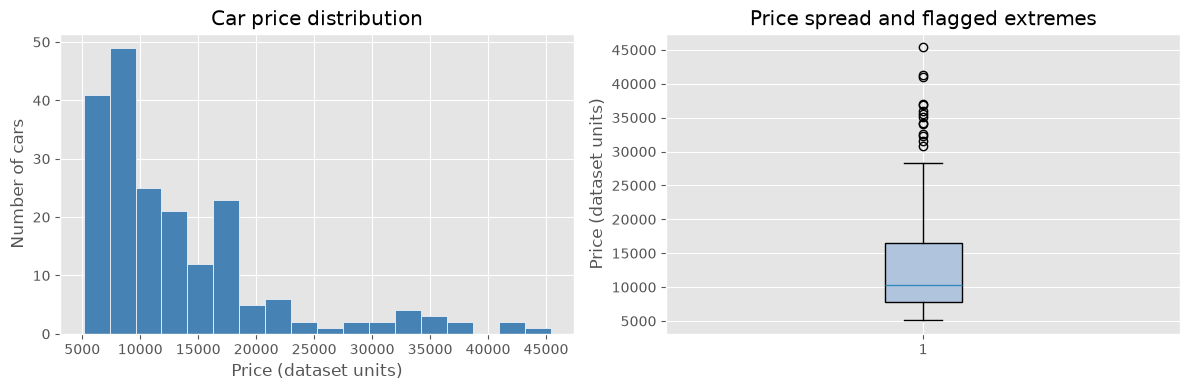

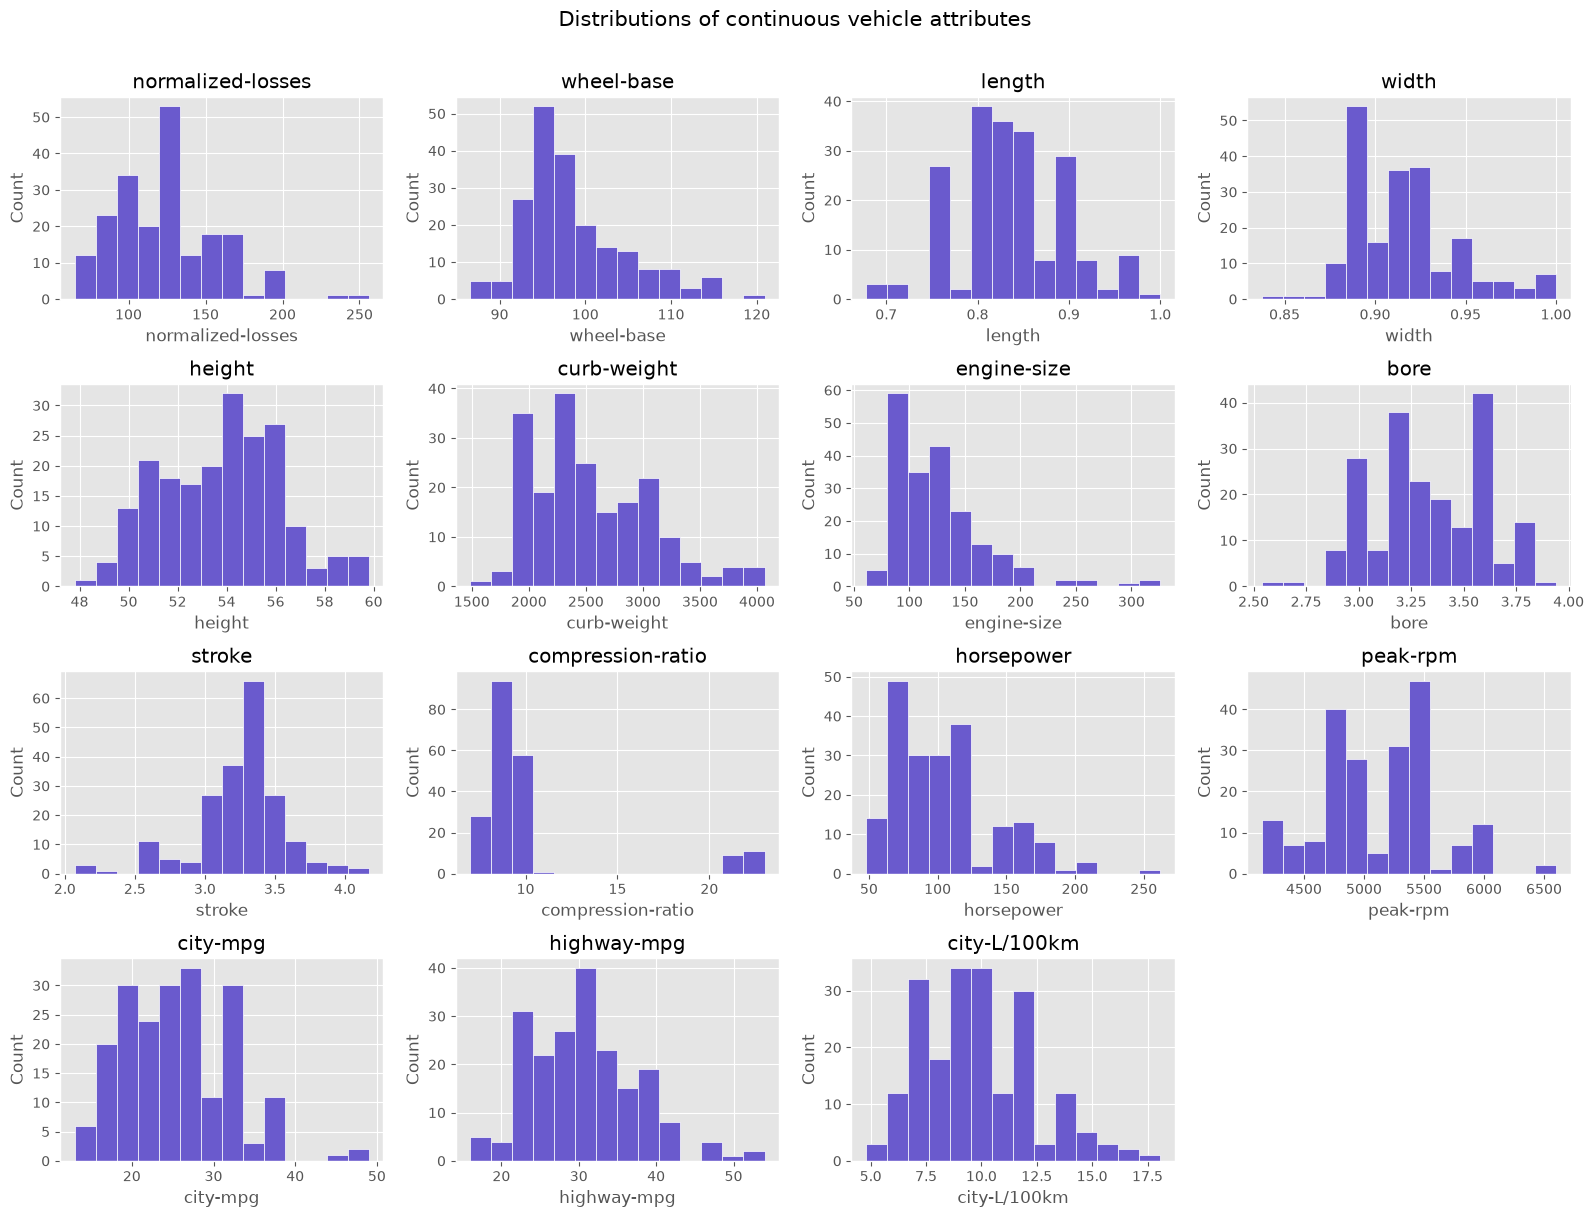

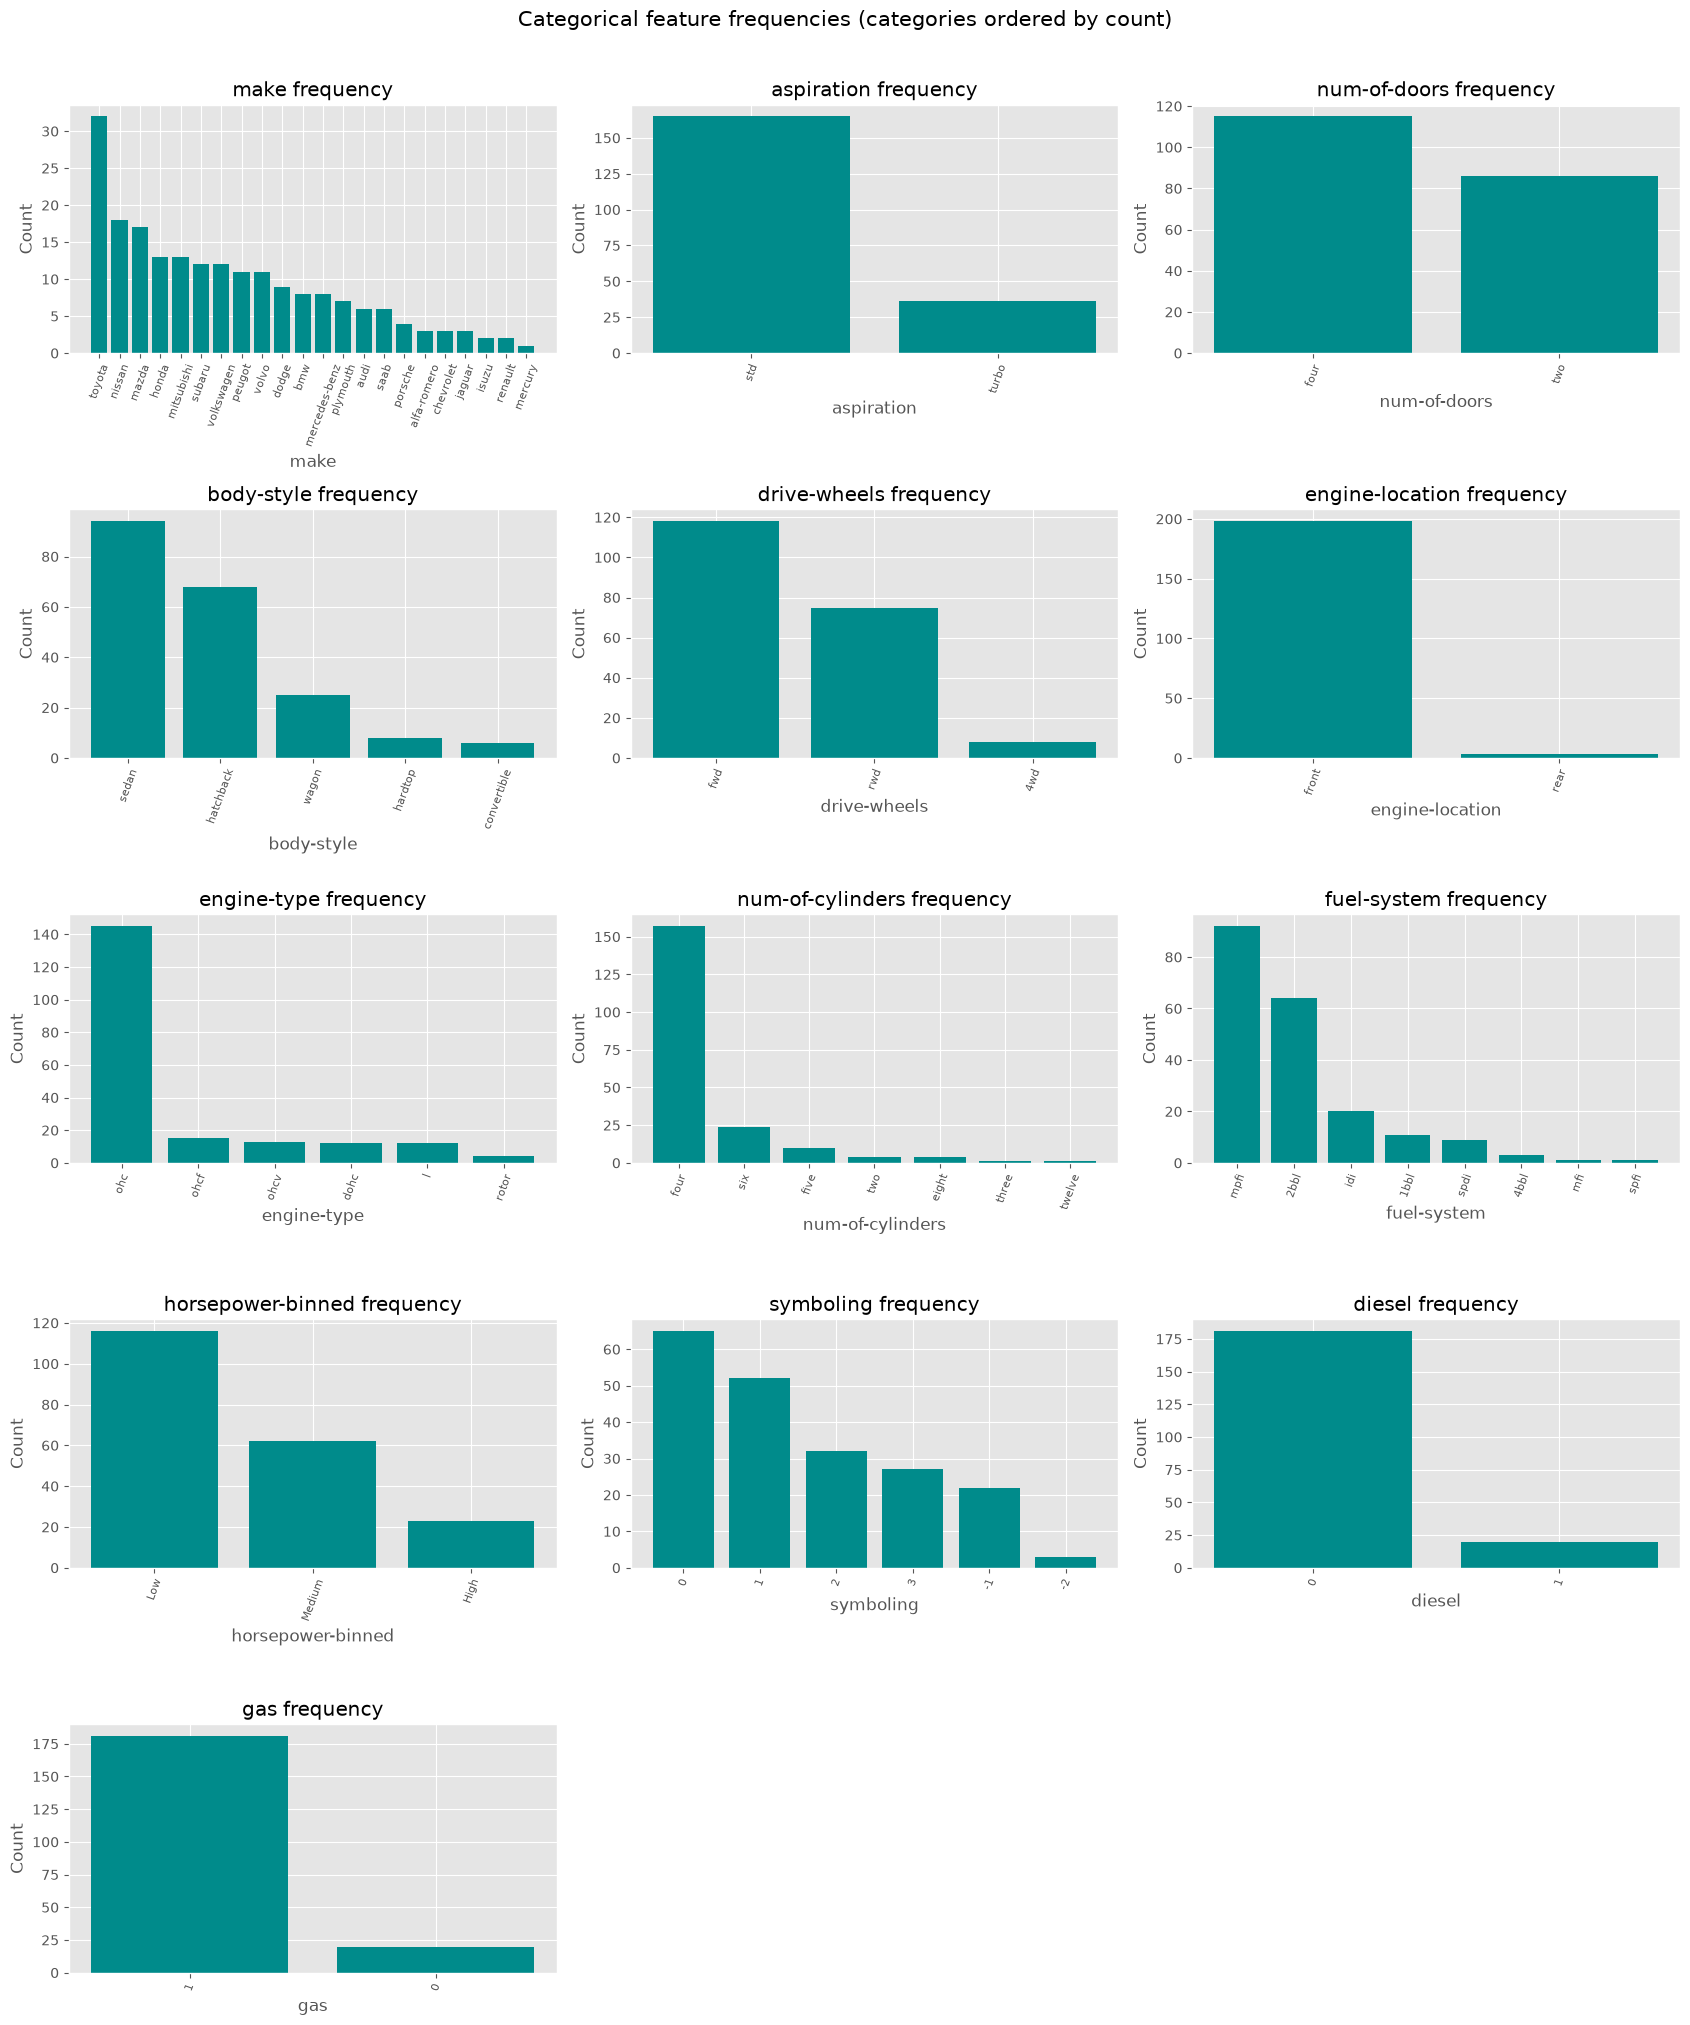

In [4]:
df = cleaned_df
categorical_columns = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()
categorical_columns += [
    column for column in ["symboling", "diesel", "gas"]
    if column in df.columns and column not in categorical_columns
]

numeric_summary = df[continuous_columns].describe().T
print("Summary statistics for continuous numeric variables:")
display(numeric_summary)

frequency_counts = pd.concat(
    {column: df[column].value_counts(dropna=False) for column in categorical_columns},
    names=["feature", "category"],
).rename("count").to_frame()
print("Frequency counts for all categorical variables:")
display(frequency_counts)

print(
    f"Price range: {df['price'].min():,.0f} to {df['price'].max():,.0f}; "
    f"mean: {df['price'].mean():,.0f}; median: {df['price'].median():,.0f}; "
    f"skewness: {df['price'].skew():.2f}."
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["price"], bins=18, color="steelblue", edgecolor="white")
axes[0].set(title="Car price distribution", xlabel="Price (dataset units)", ylabel="Number of cars")
axes[1].boxplot(df["price"], patch_artist=True, boxprops={"facecolor": "lightsteelblue"})
axes[1].set(title="Price spread and flagged extremes", ylabel="Price (dataset units)")
fig.tight_layout()
plt.show()

hist_columns = [column for column in continuous_columns if column != "price"]
columns_per_row = 4
rows = int(np.ceil(len(hist_columns) / columns_per_row))
fig, axes = plt.subplots(rows, columns_per_row, figsize=(16, rows * 3.0))
for ax, column in zip(np.asarray(axes).ravel(), hist_columns):
    ax.hist(df[column], bins=14, color="slateblue", edgecolor="white")
    ax.set(title=column, xlabel=column, ylabel="Count")
for ax in np.asarray(axes).ravel()[len(hist_columns):]:
    ax.set_visible(False)
fig.suptitle("Distributions of continuous vehicle attributes", y=1.01, fontsize=15)
fig.tight_layout()
plt.show()

category_columns_per_row = 3
category_rows = int(np.ceil(len(categorical_columns) / category_columns_per_row))
fig, axes = plt.subplots(
    category_rows, category_columns_per_row,
    figsize=(17, category_rows * 4.0), squeeze=False
)
for ax, column in zip(axes.ravel(), categorical_columns):
    counts = df[column].value_counts().sort_values(ascending=False)
    ax.bar(counts.index.astype(str), counts.values, color="darkcyan")
    ax.set(title=f"{column} frequency", xlabel=column, ylabel="Count")
    ax.tick_params(axis="x", labelrotation=70, labelsize=8)
for ax in axes.ravel()[len(categorical_columns):]:
    ax.set_visible(False)
fig.suptitle("Categorical feature frequencies (categories ordered by count)", y=1.01, fontsize=15)
fig.tight_layout()
plt.show()

## 3–5. Price relationships, group comparisons, and feature selection

Drive-wheel and body-style means are paired with medians and sample sizes so small groups are visible. Scatterplots and Pearson/Spearman correlations summarize continuous-feature relationships. Categorical group summaries report counts, means, and medians for every category; selected plots omit categories with fewer than three cars only to keep the visual readable, while the complete table remains available. A drive-wheel × body-style heatmap displays each cell's mean and count.

The final filter ranks numeric features by squared Spearman correlation and categorical features by η² (the proportion of price variation between category groups). Price-derived/redundant fields (`horsepower-binned`, fuel dummy flags, and `city-L/100km`) are excluded from selection. This is a univariate association screen—not a causal estimate or a substitute for validated multivariable prediction. High-cardinality and very small category groups should be interpreted cautiously.

Price by drive-wheels (mean, median, and sample size):


,count,mean_price,median_price
drive-wheels,,,
rwd,75,19757.6,16900.0
4wd,8,10241.0,9005.5
fwd,118,9244.8,8192.0


Highest mean: rwd (19,757.6); lowest mean: fwd (9,244.8).
Price by body-style (mean, median, and sample size):


,count,mean_price,median_price
body-style,,,
hardtop,8,22208.5,19687.5
convertible,6,21890.5,17084.5
sedan,94,14459.8,11078.5
wagon,25,12372.0,11694.0
hatchback,68,9957.4,8672.0


Highest mean: hardtop (22,208.5); lowest mean: hatchback (9,957.4).


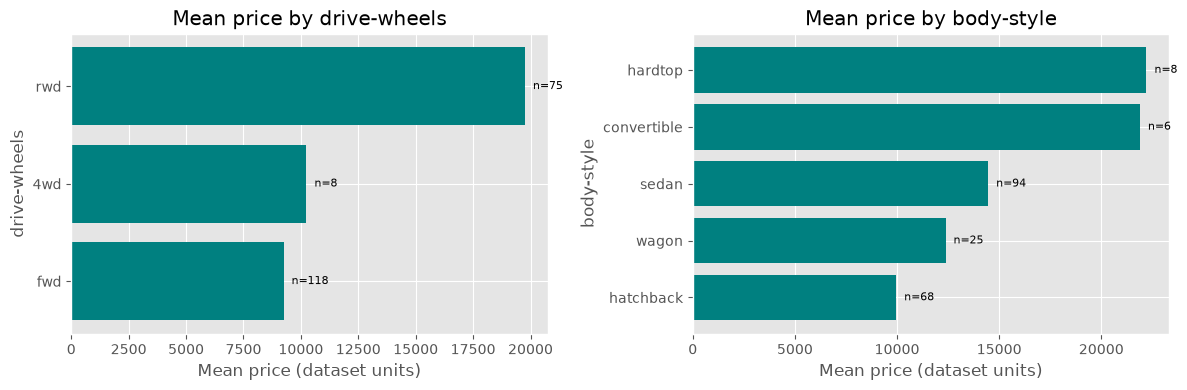

Continuous predictors ranked by absolute Spearman correlation with price:


,spearman_rho,pearson_r,abs_spearman
curb-weight,0.914,0.834,0.914
horsepower,0.849,0.810,0.849
city-mpg,-0.831,-0.687,0.831
engine-size,0.828,0.872,0.828
highway-mpg,-0.827,-0.705,0.827
width,0.812,0.751,0.812
length,0.810,0.691,0.810
wheel-base,0.682,0.585,0.682
bore,0.646,0.543,0.646
height,0.264,0.135,0.264


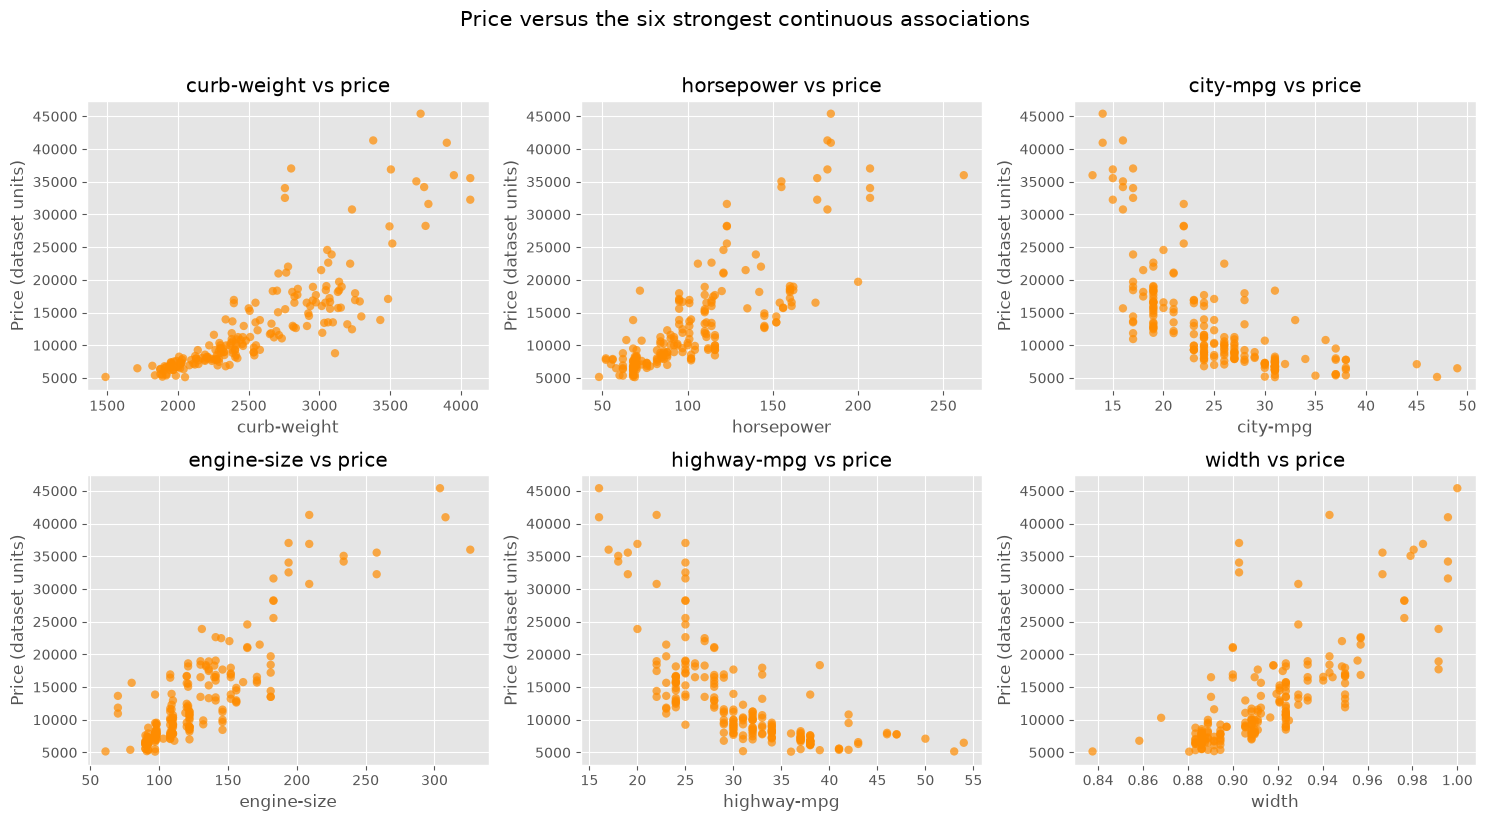

Price by every category of every categorical feature:


count  mean_price  median_price
feature   category                                      
make      jaguar             3     34600.0       35550.0
          mercedes-benz      8     33647.0       32892.0
          porsche            4     31400.5       33278.0
          bmw                8     26118.8       22835.0
          volvo             11     18063.2       18420.0
...                        ...         ...           ...
symboling 1                 52      9648.7        7447.0
diesel    1                 20     15838.2       13852.5
          0                181     12916.4        9989.0
gas       0                 20     15838.2       13852.5
          1                181     12916.4        9989.0

[70 rows x 3 columns]

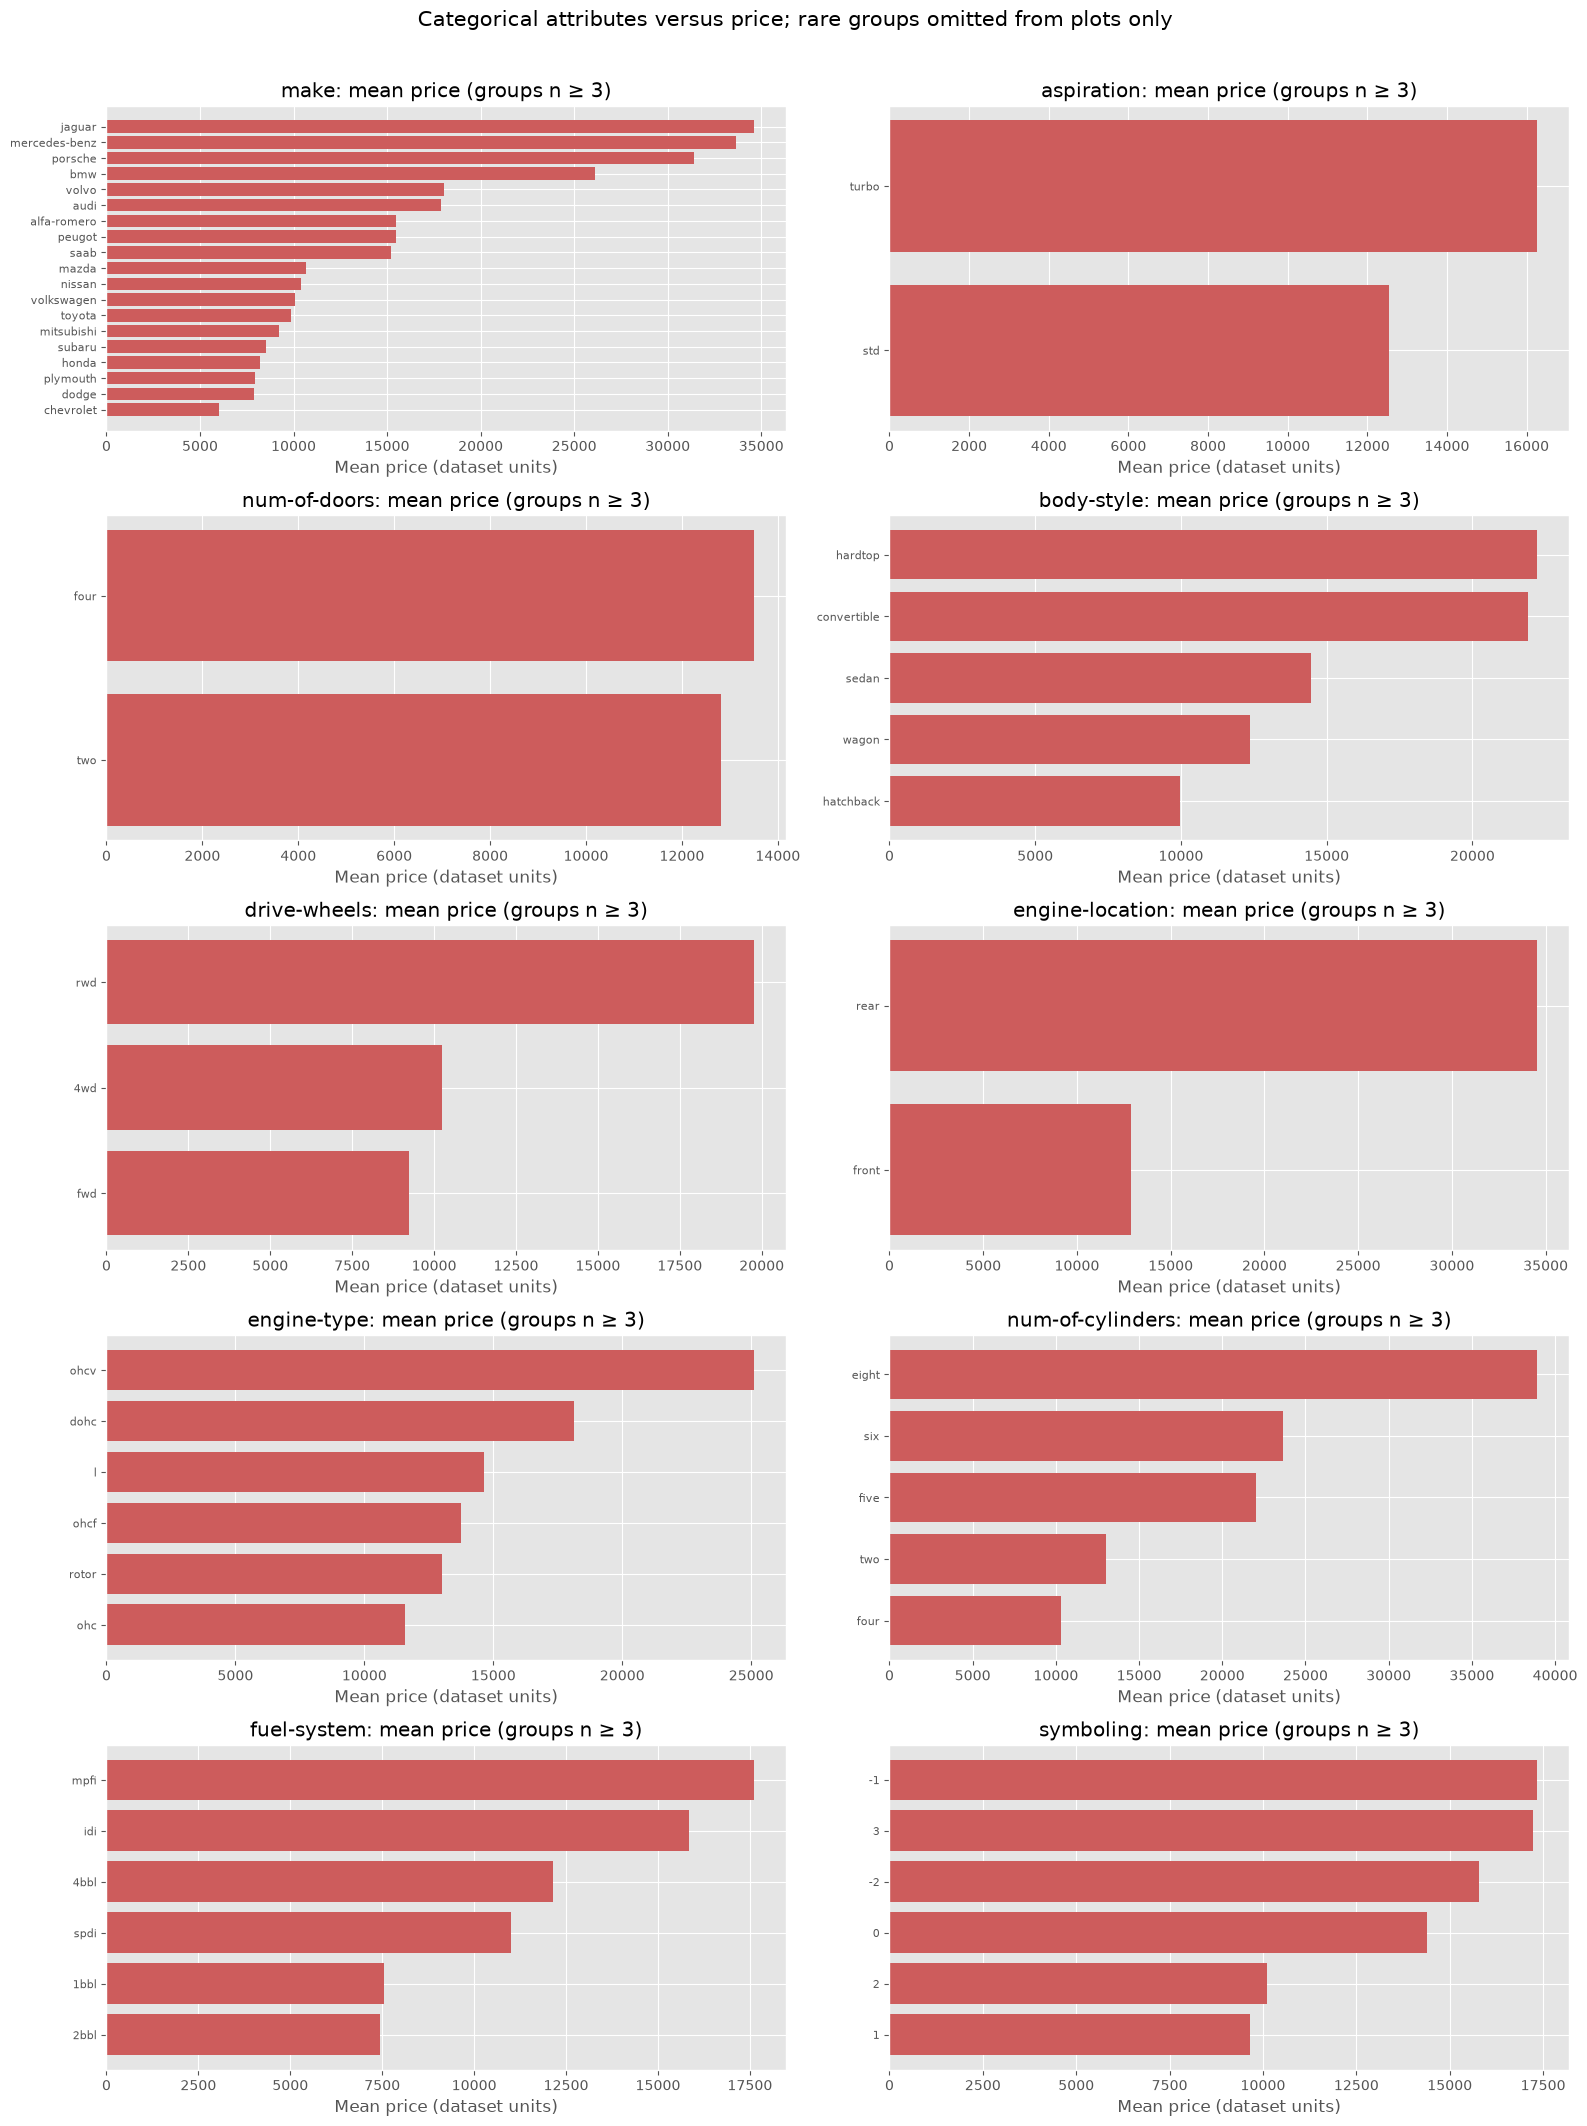

Mean price table for body-style × drive-wheels:


drive-wheels,4wd,fwd,rwd
body-style,,,
convertible,NaN,11595.0,23949.6
hardtop,NaN,8249.0,24202.7
hatchback,7603.0,8396.4,14337.8
sedan,12647.3,9811.8,21711.8
wagon,9095.8,9997.3,16994.2


Corresponding cell counts (small cells are less stable):


drive-wheels,4wd,fwd,rwd
body-style,,,
convertible,0,1,5
hardtop,0,1,7
hatchback,1,49,18
sedan,3,55,36
wagon,4,12,9


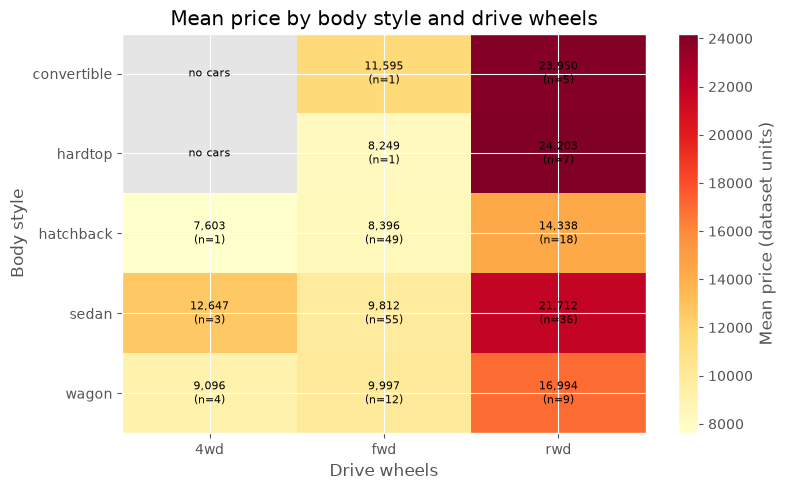

Univariate feature-selection ranking (larger scores indicate stronger sample association):


,feature,feature_type,association_measure,association_score
0,curb-weight,numeric,Spearman rho squared,0.835
1,make,categorical,eta squared,0.796
2,horsepower,numeric,Spearman rho squared,0.721
3,city-mpg,numeric,Spearman rho squared,0.691
4,engine-size,numeric,Spearman rho squared,0.686
5,highway-mpg,numeric,Spearman rho squared,0.684
6,width,numeric,Spearman rho squared,0.660
7,length,numeric,Spearman rho squared,0.657
8,num-of-cylinders,categorical,eta squared,0.630
9,wheel-base,numeric,Spearman rho squared,0.465


Top eight screened features: curb-weight, make, horsepower, city-mpg, engine-size, highway-mpg, width, length

Dealer recommendation: use engine size, curb weight, horsepower, and fuel economy as initial specification-based price anchors, then adjust for make/body style and drive-wheel segment. The filter and scatterplots show the strongest sample-level associations; verify an asking price against comparable vehicles and condition before setting it. Rear-wheel-drive cars average 19,758 versus 9,245 for front-wheel drive, while hardtop cars average 22,208 and hatchback cars 9,957. These are group averages, not causal premiums; the dataset is small, historical, and some categories have few cars.


In [5]:
# Average price by the requested categorical parameters.
group_summaries = {}
for feature in ["drive-wheels", "body-style"]:
    group_summaries[feature] = (
        df.groupby(feature, observed=True)["price"]
        .agg(count="count", mean_price="mean", median_price="median")
        .sort_values("mean_price", ascending=False)
    )
    print(f"Price by {feature} (mean, median, and sample size):")
    display(group_summaries[feature].round(1))
    highest = group_summaries[feature]["mean_price"].idxmax()
    lowest = group_summaries[feature]["mean_price"].idxmin()
    print(
        f"Highest mean: {highest} ({group_summaries[feature].loc[highest, 'mean_price']:,.1f}); "
        f"lowest mean: {lowest} ({group_summaries[feature].loc[lowest, 'mean_price']:,.1f})."
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature in zip(axes, ["drive-wheels", "body-style"]):
    summary = group_summaries[feature].sort_values("mean_price")
    ax.barh(summary.index.astype(str), summary["mean_price"], color="teal")
    ax.set(title=f"Mean price by {feature}", xlabel="Mean price (dataset units)", ylabel=feature)
    for y, value in enumerate(summary["mean_price"]):
        ax.text(value, y, f"  n={int(summary.iloc[y]['count'])}", va="center", fontsize=8)
fig.tight_layout()
plt.show()

# Continuous predictors: rank associations and visualize the strongest six.
selection_exclusions = {"city-L/100km", "diesel", "gas", "horsepower-binned"}
numeric_predictors = [
    column for column in continuous_columns
    if column != "price" and column not in selection_exclusions
]
ranked_values = df[numeric_predictors + ["price"]].rank(method="average")
spearman = ranked_values.corr()["price"].drop("price")
pearson = df[numeric_predictors + ["price"]].corr(method="pearson")["price"].drop("price")
continuous_associations = pd.DataFrame(
    {"spearman_rho": spearman, "pearson_r": pearson}
).assign(abs_spearman=lambda table: table["spearman_rho"].abs())
continuous_associations = continuous_associations.sort_values("abs_spearman", ascending=False)
print("Continuous predictors ranked by absolute Spearman correlation with price:")
display(continuous_associations.round(3))

top_scatter_features = continuous_associations.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.ravel(), top_scatter_features):
    ax.scatter(df[feature], df["price"], alpha=0.7, color="darkorange", edgecolors="none")
    ax.set(title=f"{feature} vs price", xlabel=feature, ylabel="Price (dataset units)")
fig.suptitle("Price versus the six strongest continuous associations", y=1.02, fontsize=15)
fig.tight_layout()
plt.show()

# Categorical predictors: show the complete mean/median/count table.
categorical_price_summaries = {
    feature: df.groupby(feature, observed=True)["price"]
    .agg(count="count", mean_price="mean", median_price="median")
    .sort_values("mean_price", ascending=False)
    for feature in categorical_columns
}
categorical_price_table = pd.concat(
    categorical_price_summaries, names=["feature", "category"]
).round(1)
print("Price by every category of every categorical feature:")
display(categorical_price_table)

plot_categories = [
    feature for feature in categorical_columns
    if feature not in selection_exclusions
]
plot_columns = 2
plot_rows = int(np.ceil(len(plot_categories) / plot_columns))
fig, axes = plt.subplots(plot_rows, plot_columns, figsize=(16, plot_rows * 4.2), squeeze=False)
for ax, feature in zip(axes.ravel(), plot_categories):
    summary = categorical_price_summaries[feature]
    summary = summary.loc[summary["count"] >= 3].sort_values("mean_price")
    ax.barh(summary.index.astype(str), summary["mean_price"], color="indianred")
    ax.set(title=f"{feature}: mean price (groups n ≥ 3)", xlabel="Mean price (dataset units)")
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.ravel()[len(plot_categories):]:
    ax.set_visible(False)
fig.suptitle("Categorical attributes versus price; rare groups omitted from plots only", y=1.01, fontsize=15)
fig.tight_layout()
plt.show()

# Two categorical variables: mean-price heatmap with sample sizes in each cell.
price_heatmap = df.pivot_table(
    index="body-style", columns="drive-wheels", values="price", aggfunc="mean"
)
count_heatmap = df.pivot_table(
    index="body-style", columns="drive-wheels", values="price", aggfunc="count"
)
print("Mean price table for body-style × drive-wheels:")
display(price_heatmap.round(1))
print("Corresponding cell counts (small cells are less stable):")
display(count_heatmap.fillna(0).astype(int))

fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(price_heatmap.to_numpy(), cmap="YlOrRd", aspect="auto")
ax.set_xticks(np.arange(len(price_heatmap.columns)), labels=price_heatmap.columns)
ax.set_yticks(np.arange(len(price_heatmap.index)), labels=price_heatmap.index)
ax.set(title="Mean price by body style and drive wheels", xlabel="Drive wheels", ylabel="Body style")
for row in range(len(price_heatmap.index)):
    for column in range(len(price_heatmap.columns)):
        value = price_heatmap.iloc[row, column]
        count = count_heatmap.iloc[row, column]
        label = "no cars" if pd.isna(value) else f"{value:,.0f}\n(n={int(count)})"
        ax.text(column, row, label, ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Mean price (dataset units)")
fig.tight_layout()
plt.show()

# Univariate, supervised filter feature selection.
total_price_variation = ((df["price"] - df["price"].mean()) ** 2).sum()
selection_rows = []
for feature in numeric_predictors:
    rho = df[feature].rank(method="average").corr(
        df["price"].rank(method="average")
    )
    selection_rows.append(
        {
            "feature": feature,
            "feature_type": "numeric",
            "association_measure": "Spearman rho squared",
            "association_score": float(rho**2),
        }
    )
for feature in categorical_columns:
    if feature in selection_exclusions:
        continue
    grouped = df.groupby(feature, observed=True)["price"].agg(["count", "mean"])
    between_group_variation = (
        grouped["count"] * (grouped["mean"] - df["price"].mean()) ** 2
    ).sum()
    selection_rows.append(
        {
            "feature": feature,
            "feature_type": "categorical",
            "association_measure": "eta squared",
            "association_score": float(between_group_variation / total_price_variation),
        }
    )
feature_selection = pd.DataFrame(selection_rows).sort_values(
    "association_score", ascending=False
).reset_index(drop=True)
print("Univariate feature-selection ranking (larger scores indicate stronger sample association):")
display(feature_selection.head(12).round(3))
selected_features = feature_selection.head(8)["feature"].tolist()
print(f"Top eight screened features: {', '.join(selected_features)}")

drive_means = group_summaries["drive-wheels"]["mean_price"]
body_means = group_summaries["body-style"]["mean_price"]
print(
    "\nDealer recommendation: use engine size, curb weight, horsepower, and fuel economy "
    "as initial specification-based price anchors, then adjust for make/body style and "
    "drive-wheel segment. The filter and scatterplots show the strongest sample-level "
    "associations; verify an asking price against comparable vehicles and condition before "
    "setting it. Rear-wheel-drive cars average "
    f"{drive_means['rwd']:,.0f} versus {drive_means['fwd']:,.0f} for front-wheel drive, "
    f"while {body_means.idxmax()} cars average {body_means.max():,.0f} and "
    f"{body_means.idxmin()} cars {body_means.min():,.0f}. These are group averages, not "
    "causal premiums; the dataset is small, historical, and some categories have few cars."
)